# 01 · Data acquisition and exploratory data analysis

**Dataset:** UCI Heart Disease (Cleveland), 303 patients, 13 clinical features plus a 0-4
diagnosis (`num`). **Goal of this notebook:** obtain the data, document every cleaning
decision, and understand the features before modelling.

The cleaning and plotting logic lives in `src/data_processing.py` and `src/eda.py`, so the
notebook, the CI pipeline and the tests all use identical code.

In [1]:
import sys, warnings
from pathlib import Path

here = Path.cwd().resolve()
ROOT = next((p for p in [here, *here.parents] if (p / "src" / "config.py").exists()), here)
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import json
import pandas as pd
from IPython.display import Image, display

from src import config
pd.set_option("display.max_columns", 30)

## 1. Acquire the data
Run once from the repo root: `python -m src.download_data`.

In [2]:
from src.download_data import download
from src.data_processing import load_raw, clean, save_clean, missing_value_report

raw_path = download()           # no-op if the file is already there
df_raw = load_raw(raw_path)
print("shape:", df_raw.shape)
df_raw.head()

shape: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [3]:
df_raw.dtypes.to_frame('dtype').T

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
dtype,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,int64


## 2. Data quality

`?` marks missing values in the source file. They are parsed as `NaN`.

In [4]:
missing_value_report(df_raw)

,missing,percent
ca,4,1.32
thal,2,0.66


## 3. Cleaning decisions

| Issue | Decision | Why |
|---|---|---|
| `?` in `ca`, `thal` | Parsed as NaN, then **mode imputation** | Categorical codes: mode keeps valid category values; only a handful of rows affected |
| Missing numeric values (none expected) | Median imputation | Robust to the skew in `chol` / `oldpeak` |
| `num` is 0-4 (severity) | Binarise: `target = (num > 0)` | Task asks for presence / absence |
| Duplicates | Dropped | Prevent leakage between CV folds |
| Implausible ranges | Masked to NaN, then imputed | Defensive; also enforced in the API |

The scikit-learn pipeline **repeats imputation inside cross-validation**, so no statistic from a
validation fold leaks into training. The saved CSV is imputed only for convenience and EDA.

In [5]:
df = clean(df_raw)
save_clean(df)
print("clean shape:", df.shape, "| missing values left:", int(df.isna().sum().sum()))
df.target.value_counts().rename({0: "no disease", 1: "disease"})

clean shape: (303, 14) | missing values left: 0


target
no disease    164
disease       139
Name: count, dtype: int64

In [6]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,303.0,54.44,9.04,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.68,0.47,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.16,0.96,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.69,17.60,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.69,51.78,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.15,0.36,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.99,0.99,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.61,22.88,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.33,0.47,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.04,1.16,0.0,0.0,0.8,1.6,6.2


## 4. Visual EDA

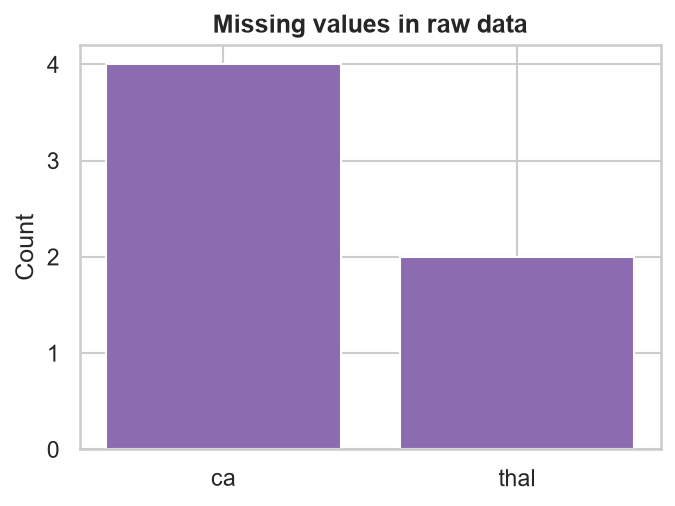

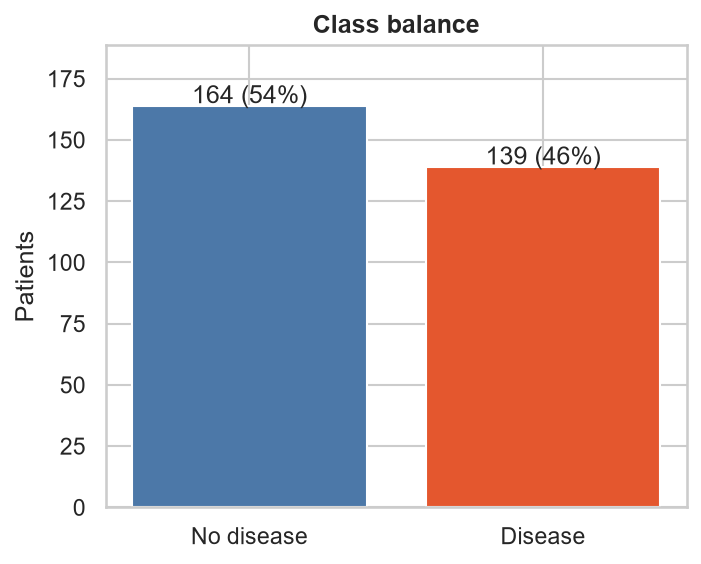

In [7]:
from src import eda
eda._style()
raw_missing = eda.plot_missing_values(df_raw)
if raw_missing: display(Image(filename=str(raw_missing)))
display(Image(filename=str(eda.plot_class_balance(df))))

**Class balance.** The classes are close to balanced, so accuracy is meaningful, but recall is still the clinically important metric (missing a sick patient is costlier than a false alarm).

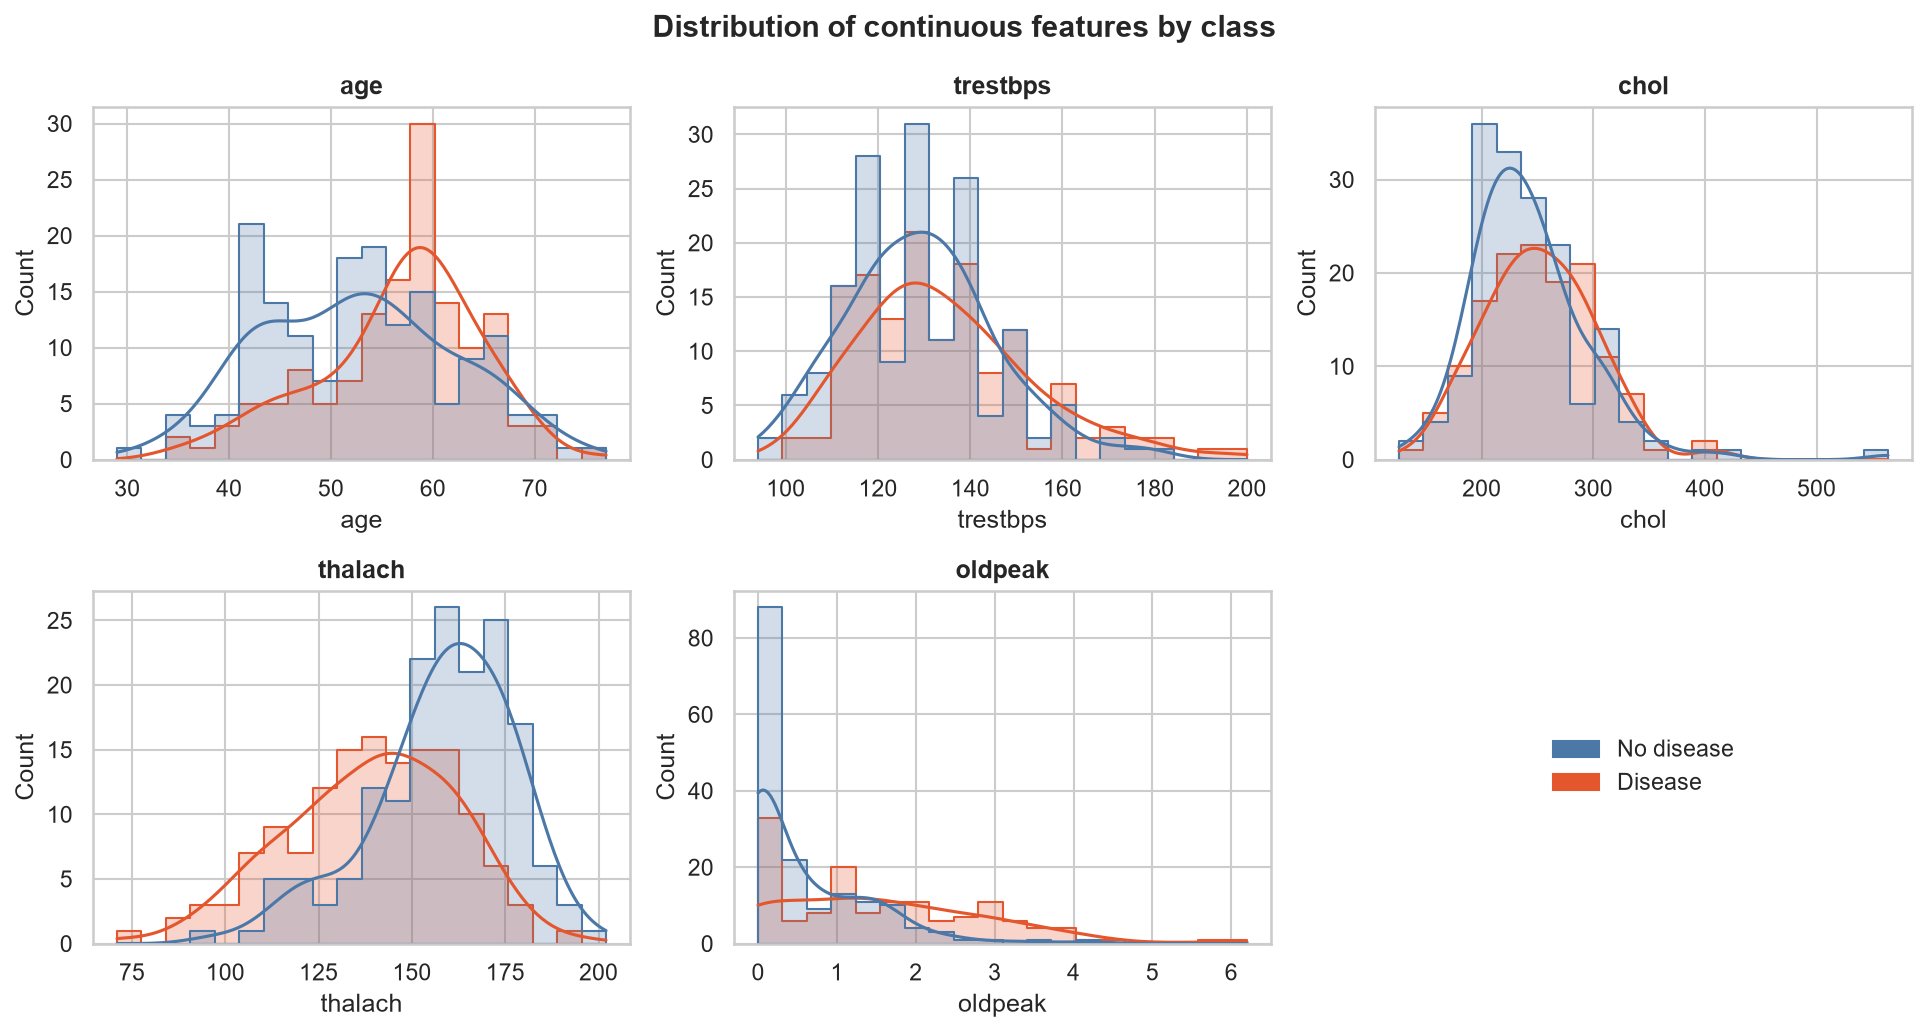

In [8]:
display(Image(filename=str(eda.plot_numeric_histograms(df))))

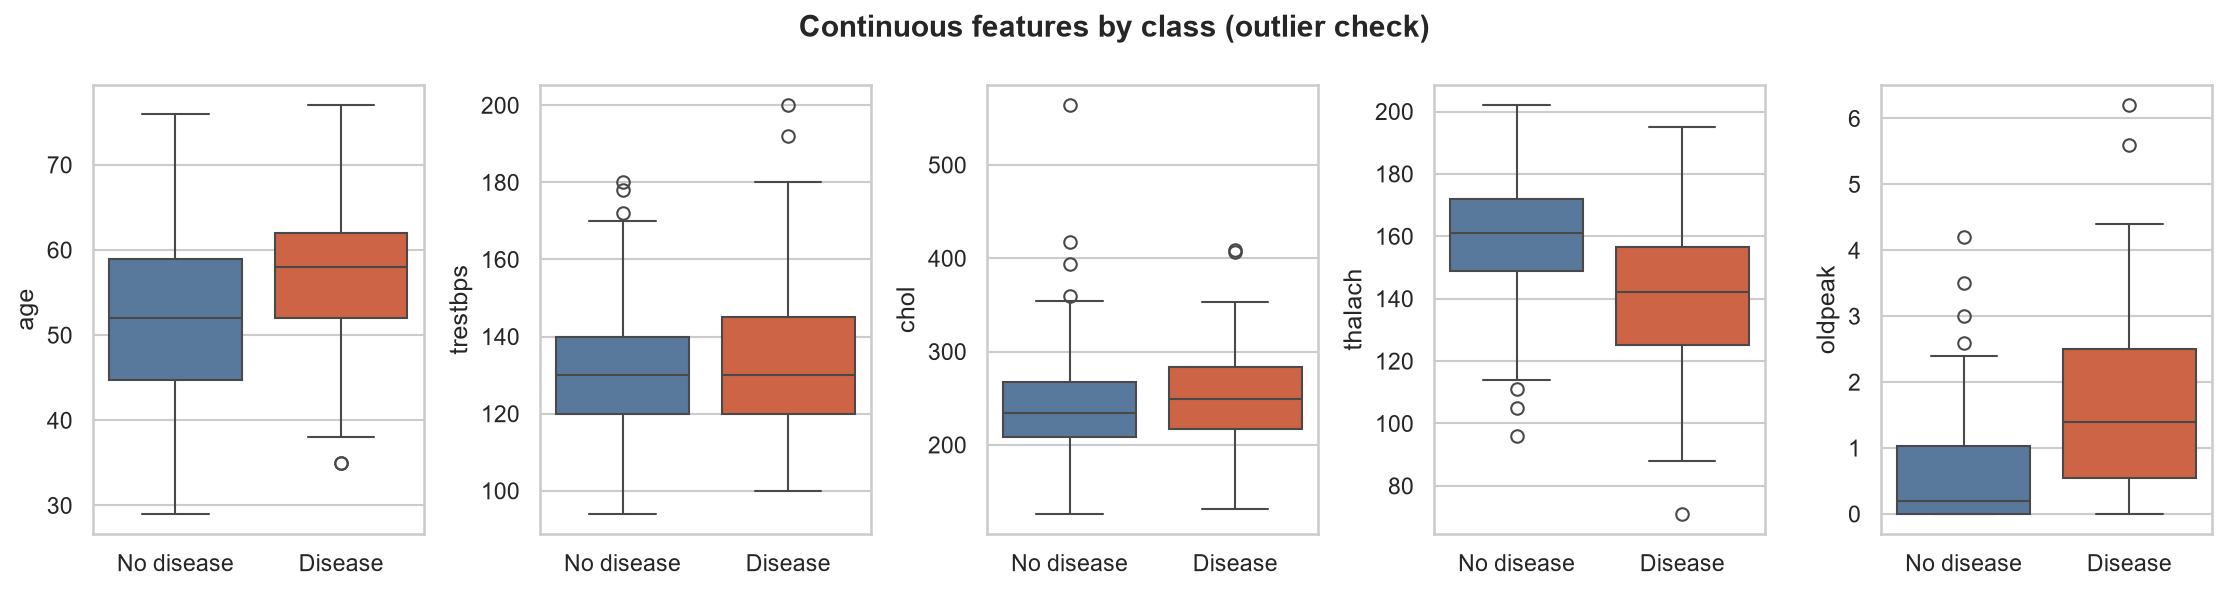

In [9]:
display(Image(filename=str(eda.plot_boxplots(df))))

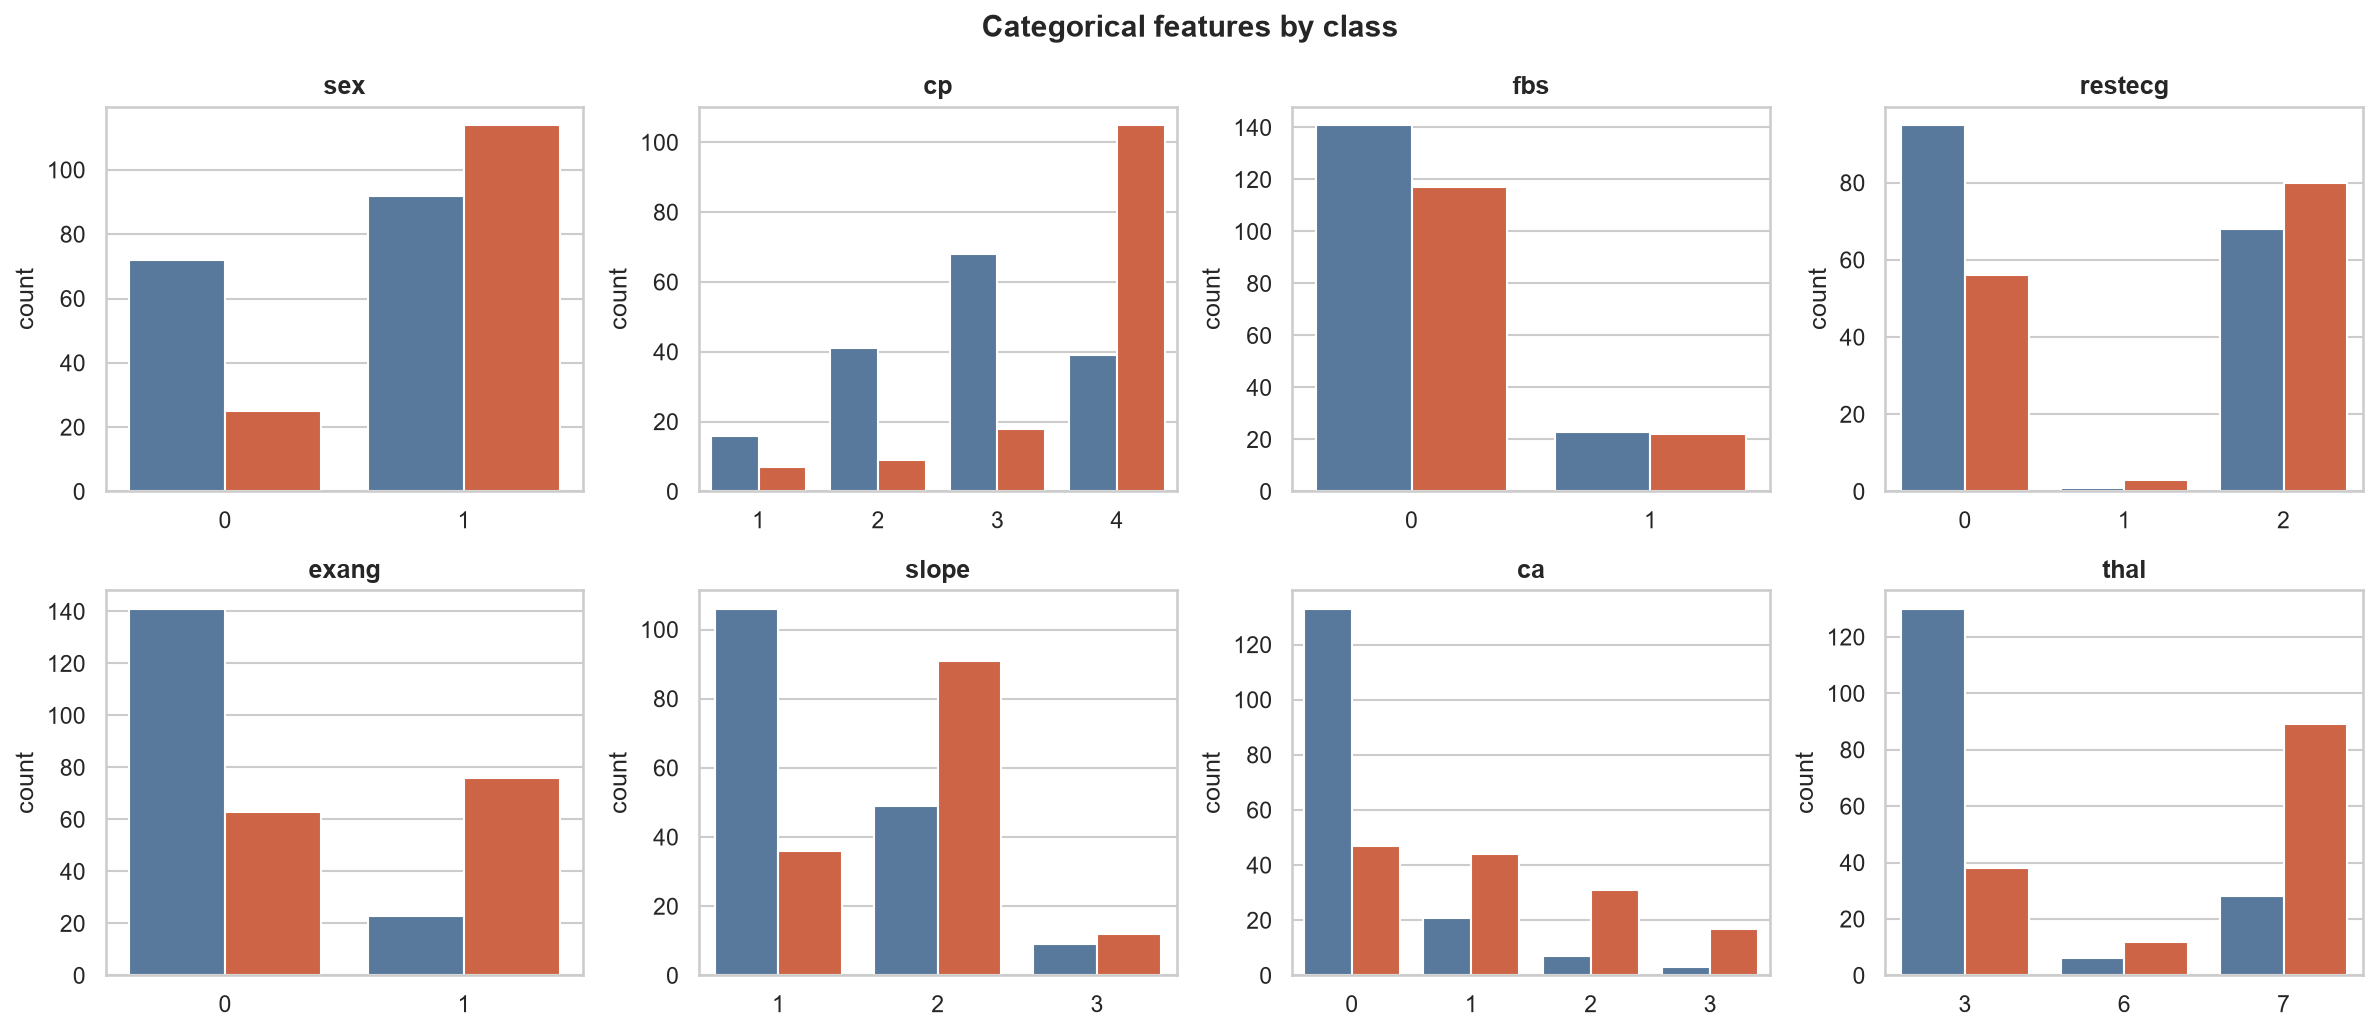

In [10]:
display(Image(filename=str(eda.plot_categorical_counts(df))))

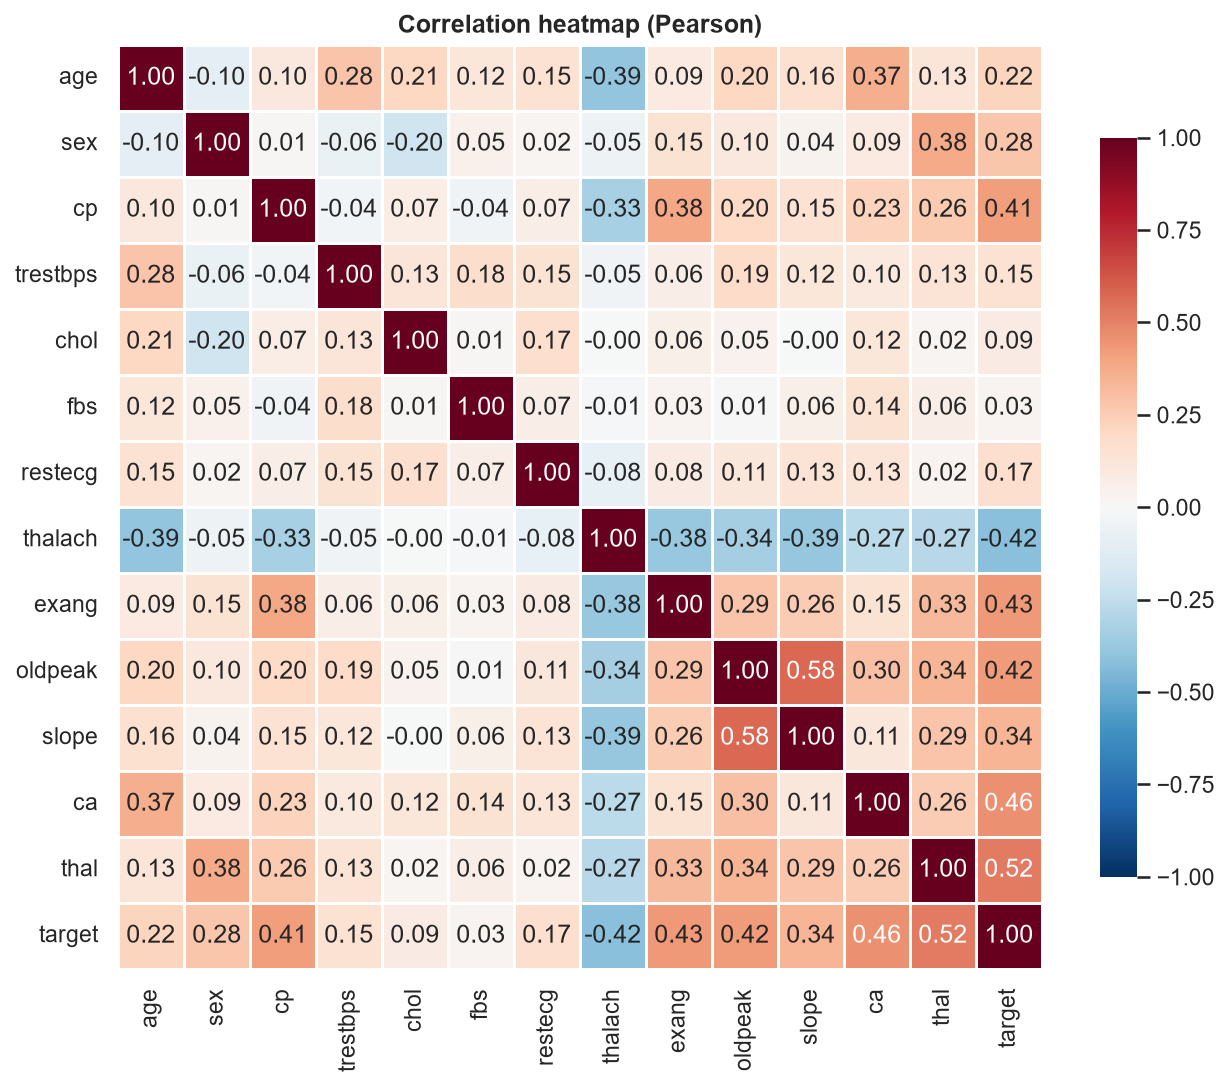

In [11]:
display(Image(filename=str(eda.plot_correlation_heatmap(df))))

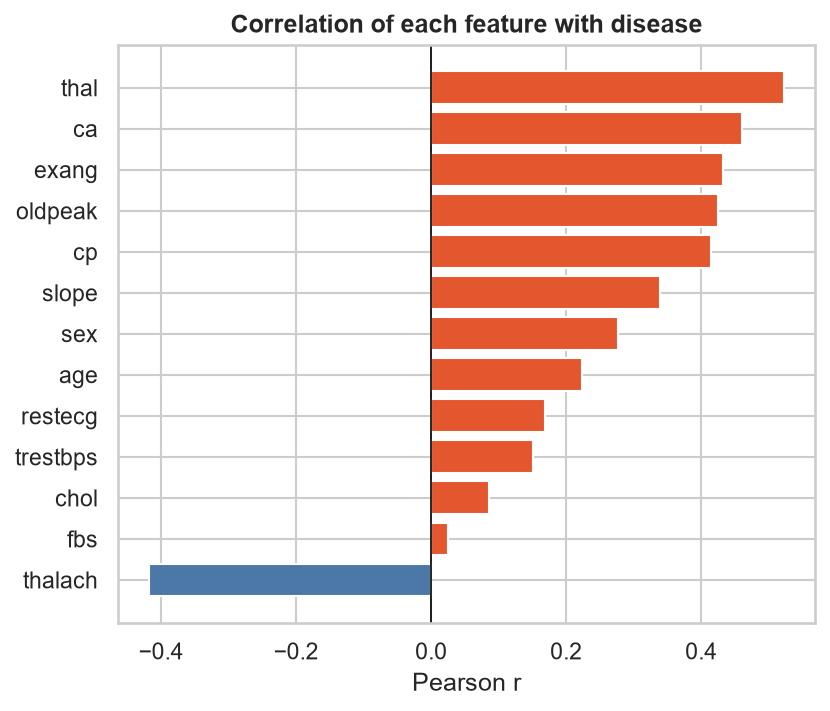

In [12]:
display(Image(filename=str(eda.plot_target_correlation(df))))

## 5. Summary statistics for the report

In [13]:
summary = eda.summarise(df_raw, df)
print(json.dumps({k: v for k, v in summary.items() if k != "numeric_describe"}, indent=2))

{
  "rows_raw": 303,
  "rows_clean": 303,
  "n_features": 13,
  "missing_raw": {
    "ca": 4,
    "thal": 2
  },
  "class_balance": {
    "No disease": 164,
    "Disease": 139
  },
  "positive_rate": 0.4587,
  "top_correlations_with_target": {
    "thal": 0.522,
    "ca": 0.46,
    "exang": 0.432,
    "oldpeak": 0.425,
    "thalach": -0.417
  }
}


## 6. Observations (confirm against your own plots before quoting them)

Patterns widely reported for the Cleveland data, which the figures above should show:

* Patients with disease tend to have **lower maximum heart rate (`thalach`)** and **higher ST depression (`oldpeak`)**.
* **Asymptomatic chest pain (`cp = 4`)**, **exercise-induced angina (`exang = 1`)**, a **reversible thalassemia defect (`thal = 7`)** and more **fluoroscopy-coloured vessels (`ca > 0`)** are associated with disease.
* `chol` and `fbs` are only weakly related to the target on their own.
* Features are only moderately correlated with each other, so multicollinearity is not a concern for logistic regression.

**Implications for modelling:** scale continuous features (needed for logistic regression),
one-hot encode the categorical codes (they are not ordinal: `thal` 3/6/7 is a label), and
evaluate with stratified cross-validation because the dataset is small.